# Normalization Ablation Analysis

Compares normalization strategies on three datasets (HLS-BurnScars, MADOS, SpaceNet7-CD).

| Condition | Folder suffix | Description |
|-----------|--------------|-------------|
| `dataset_stats` | `pangaea_full_seg/upernet/` (baseline) | Per-dataset mean/std from training split |
| `imagewise` | `*_imagewise` | Per-image z-score at runtime (no fixed stats) |
| `no_norm` | `*_nonorm` | Raw pixel values, BandFilter only |
| `custombandwise` | `*_custombandwise` | Fixed per-band stats across multiple S2 datasets |
| `customglobal` | `*_customglobal` | Single global scalar mean/std across all S2 datasets |

CARL uses `carl_no_internal_norm` in all conditions so its internal `_standardize()` is disabled,
giving a fair comparison where normalization is controlled exclusively by the preprocessing config.

In [10]:
import re
import os
from pathlib import Path
import pandas as pd
import numpy as np

EXPERIMENTS_BASE = Path("/dss/dsstbyfs02/pn49cu/pn49cu-dss-0001/niklas/experiments")

# carl_no_internal_norm is the CARL variant used in all ablation conditions
ENCODER_LABELS = {
    "carl_no_internal_norm": "CARL",
    "dofa":               "DOFA",
    "dofav2":             "DOFAv2",
    "carl":               "CARL",
    "panopticon":         "Panopticon",
    "copernicus_fm_base": "Copernicus-FM",
    "smarties_vitb":      "SMARTIES",
    "dinov2_vitb14":      "DINOv2",
    "unet_encoder":       "UNet",
    "unet_encoder_mi":    "UNet",
    "vit_scratch":        "ViT-Scratch",
    "vit_scratch_mi":     "ViT-Scratch",
}

DATASET_LABELS = {
    "hlsburnscars":      "HLS-BurnScars",
    "sen1floods11":      "Sen1Floods11",
    "mados":             "MADOS",
    "pastis":            "PASTIS",
    "dynamicen":         "DynamicEarthNet",
    "croptypemapping":   "CropTypeMapping",
    "spacenet7cd":       "SpaceNet7-CD",
    "ai4smallfarms":     "AI4SmallFarms",
    "fivebillionpixels": "FiveBillionPixels",
}

DATASET_ORDER = list(DATASET_LABELS.keys())

# carl_no_internal_norm must come before carl for greedy prefix matching
KNOWN_ENCODERS = [
    "copernicus_fm_base", "copernicus_fm_large",
    "smarties_vitb", "dinov2_vitb14",
    "carl_no_internal_norm", "carl",
    "dofav2", "dofa", "panopticon",
    "vit_scratch_mi", "vit_scratch",
    "unet_encoder_mi", "unet_encoder",
]

KNOWN_DECODERS = [
    "seg_upernet_mt_ltae", "seg_upernet",
    "seg_siamupernet_conc", "seg_siamupernet_diff",
    "seg_siam_mlp_fusion", "seg_mlp_fusion",
    "seg_siamunet_conc", "seg_siamunet_diff", "seg_unet",
    "seg_linear_probe", "seg_siam_linear_probe",
    "cls_linear_probe",
]

DATASET_RE = re.compile(
    r"_(" + "|".join(re.escape(d) for d in DATASET_ORDER) + r")_"
)

# Ablation scope
ABL_DATASETS_DISPLAY = ["HLS-BurnScars", "MADOS", "SpaceNet7-CD"]
ABL_ENCODERS_DISPLAY = ["DOFA", "DOFAv2", "CARL", "Panopticon", "SMARTIES", "Copernicus-FM"]

# All conditions in display order
CONDITIONS = [
    "dataset_stats",   # baseline
    "imagewise",
    "no_norm",
    "custombandwise",
    "customglobal",
]

print("Config loaded.")

Config loaded.


In [11]:
def parse_run_dir_name(name: str) -> dict:
    """Extract dataset, encoder, decoder from a run directory name."""
    m = DATASET_RE.search(name)
    if not m:
        return {}
    dataset = m.group(1)
    rest = name[m.end():]

    encoder = next((e for e in KNOWN_ENCODERS if rest.startswith(e + "_")), None)
    if encoder:
        rest = rest[len(encoder) + 1:]

    decoder = next((d for d in KNOWN_DECODERS if rest.startswith(d)), None)

    return {"dataset": dataset, "encoder": encoder or "", "decoder": decoder or ""}


def parse_log_metrics(log_path: Path) -> dict:
    """Parse train.log-0 for test metrics (last test block)."""
    if not log_path.exists():
        return {}

    text = log_path.read_text(errors="ignore")
    sections = re.split(r"\[test\] ------- IoU", text)
    if len(sections) < 2:
        return {}
    test_block = "[test] ------- IoU" + sections[-1]

    metrics = {}
    metric_map = {
        "IoU":       "test_mIoU",
        "F1-score":  "test_mF1",
        "Precision": "test_mPrecision",
        "Recall":    "test_mRecall",
    }
    for section_name, metric_key in metric_map.items():
        pattern = rf"\[test\] ------- {section_name}.*?\[test\] Mean\s+([\d.]+)"
        m = re.search(pattern, test_block, re.DOTALL)
        if m:
            metrics[metric_key] = float(m.group(1))
    return metrics


def load_experiment_folder(
    folder,
    encoder_map=None,
    dataset_map=None,
    metric="test_mIoU",
    keep_all_metrics=False,
):
    """
    Load all runs from an experiment folder and return a long-form DataFrame.
    Walks up to 2 levels deep to find run dirs containing train.log-0.
    """
    enc_map = {**ENCODER_LABELS, **(encoder_map or {})}
    ds_map  = {**DATASET_LABELS,  **(dataset_map  or {})}
    folder  = Path(folder)

    run_dirs = []
    for child in sorted(folder.iterdir()):
        if not child.is_dir():
            continue
        if (child / "train.log-0").exists():
            run_dirs.append(child)
        else:
            for grandchild in sorted(child.iterdir()):
                if grandchild.is_dir() and (grandchild / "train.log-0").exists():
                    run_dirs.append(grandchild)

    rows = []
    for run_dir in run_dirs:
        parsed = parse_run_dir_name(run_dir.name)
        if not parsed.get("dataset"):
            continue
        log_metrics = parse_log_metrics(run_dir / "train.log-0")
        if not log_metrics:
            continue

        enc_raw = parsed["encoder"]
        ds_raw  = parsed["dataset"]

        row = {
            "run_dir":     run_dir.name,
            "encoder_raw": enc_raw,
            "decoder":     parsed["decoder"],
            "dataset_raw": ds_raw,
            "encoder":     enc_map.get(enc_raw, enc_raw),
            "dataset":     ds_map.get(ds_raw, ds_raw),
        }
        if keep_all_metrics:
            row.update(log_metrics)
        elif metric in log_metrics:
            row[metric] = log_metrics[metric]
        else:
            continue
        rows.append(row)

    return pd.DataFrame(rows)


def to_pivot(
    df,
    metric="test_mIoU",
    index="encoder",
    columns="dataset",
    aggfunc="max",
    dataset_order=None,
    encoder_order=None,
    add_mean=True,
):
    """Pivot a long-form results DataFrame to encoder x dataset."""
    if metric not in df.columns:
        raise ValueError(f"Metric '{metric}' not in DataFrame: {list(df.columns)}")

    pivot = df.pivot_table(index=index, columns=columns, values=metric, aggfunc=aggfunc)

    if dataset_order is None:
        ordered_ds = [DATASET_LABELS[d] for d in DATASET_ORDER if DATASET_LABELS[d] in pivot.columns]
        remaining  = [c for c in pivot.columns if c not in ordered_ds]
        dataset_order = ordered_ds + remaining
    pivot = pivot.reindex(columns=[c for c in dataset_order if c in pivot.columns])

    if encoder_order is not None:
        pivot = pivot.reindex([e for e in encoder_order if e in pivot.index])

    if add_mean:
        pivot["Mean"] = pivot.mean(axis=1, skipna=True).round(3)

    return pivot.round(2)


print("Functions defined.")

Functions defined.


## Load all conditions

Each condition is loaded into its own DataFrame, then combined into a single long-form table.

In [12]:
NORM_ABL_BASE = EXPERIMENTS_BASE / "ablations" / "norm_ablation"

# Folder suffix → condition label
CONDITION_FOLDERS = {
    "dataset_stats": EXPERIMENTS_BASE / "pangaea_full_seg" / "upernet",  # baseline
    "imagewise":     NORM_ABL_BASE,   # uses *_imagewise subfolders
    "no_norm":       NORM_ABL_BASE,   # uses *_nonorm subfolders
    "custombandwise": NORM_ABL_BASE,  # uses *_custombandwise subfolders
    "customglobal":  NORM_ABL_BASE,   # uses *_customglobal subfolders
}

# Suffix used in folder names inside norm_ablation/
CONDITION_SUFFIXES = {
    "imagewise":     "imagewise",
    "no_norm":       "nonorm",
    "custombandwise": "custombandwise",
    "customglobal":  "customglobal",
}


def load_norm_condition(condition: str) -> pd.DataFrame:
    """
    Load all runs for a given normalization condition.

    For dataset_stats: loads the full UPerNet baseline folder and filters to
    the 3 ablation datasets and 6 ablation encoders.
    For other conditions: loads each <encoder>_<suffix> subfolder under norm_ablation/.
    """
    if condition == "dataset_stats":
        df = load_experiment_folder(
            EXPERIMENTS_BASE / "pangaea_full_seg" / "upernet",
            metric="test_mIoU",
        )
        df = df[
            df["encoder"].isin(ABL_ENCODERS_DISPLAY) &
            df["dataset"].isin(ABL_DATASETS_DISPLAY)
        ].copy()
        df["condition"] = condition
        return df

    suffix = CONDITION_SUFFIXES[condition]
    dfs = []
    for subdir in sorted(NORM_ABL_BASE.iterdir()):
        if subdir.is_dir() and subdir.name.endswith(f"_{suffix}"):
            df = load_experiment_folder(subdir, metric="test_mIoU")
            if not df.empty:
                dfs.append(df)

    if not dfs:
        return pd.DataFrame()

    df = pd.concat(dfs, ignore_index=True)
    df = df[
        df["encoder"].isin(ABL_ENCODERS_DISPLAY) &
        df["dataset"].isin(ABL_DATASETS_DISPLAY)
    ].copy()
    df["condition"] = condition
    return df


# Load all conditions
condition_dfs = {}
for cond in CONDITIONS:
    df_cond = load_norm_condition(cond)
    condition_dfs[cond] = df_cond
    status = f"{len(df_cond)} runs" if not df_cond.empty else "not found / not yet run"
    print(f"  {cond:20s}: {status}")

# Combined long-form table
df_all = pd.concat(
    [df for df in condition_dfs.values() if not df.empty],
    ignore_index=True,
)
print(f"\nTotal: {len(df_all)} runs across {df_all['condition'].nunique()} conditions")

  dataset_stats       : 18 runs
  imagewise           : 18 runs
  no_norm             : 18 runs
  custombandwise      : not found / not yet run
  customglobal        : not found / not yet run

Total: 54 runs across 3 conditions


## Per-condition pivot tables (encoder × dataset)

In [13]:
for cond in CONDITIONS:
    df_cond = condition_dfs.get(cond)
    if df_cond is None or df_cond.empty:
        print(f"\n=== {cond} — no data ===")
        continue
    print(f"\n=== {cond} ===")
    pivot = to_pivot(
        df_cond,
        dataset_order=ABL_DATASETS_DISPLAY,
        encoder_order=ABL_ENCODERS_DISPLAY,
    )
    display(pivot)


=== dataset_stats ===


dataset,HLS-BurnScars,MADOS,SpaceNet7-CD,Mean
encoder,,,,
DOFA,80.64,60.39,61.07,67.37
DOFAv2,78.27,48.60,63.63,63.50
CARL,80.84,50.50,58.90,63.41
Panopticon,84.22,68.22,60.77,71.07
SMARTIES,82.84,62.28,59.51,68.21
Copernicus-FM,82.33,56.90,62.36,67.20



=== imagewise ===


dataset,HLS-BurnScars,MADOS,SpaceNet7-CD,Mean
encoder,,,,
DOFA,82.56,54.62,60.72,65.97
DOFAv2,72.10,51.66,63.06,62.27
CARL,84.25,46.95,59.00,63.40
Panopticon,84.74,65.91,62.57,71.08
SMARTIES,83.02,62.46,59.19,68.22
Copernicus-FM,81.42,64.44,62.05,69.30



=== no_norm ===


dataset,HLS-BurnScars,MADOS,SpaceNet7-CD,Mean
encoder,,,,
DOFA,80.44,51.22,60.12,63.93
DOFAv2,70.84,30.64,61.61,54.36
CARL,81.27,48.78,56.28,62.11
Panopticon,82.77,61.64,59.00,67.80
SMARTIES,83.15,48.33,57.30,62.92
Copernicus-FM,82.89,56.90,59.11,66.30



=== custombandwise — no data ===

=== customglobal — no data ===


## Δ vs Baseline (dataset_stats)

Each condition minus the `dataset_stats` baseline. Positive = better than using dataset stats.

In [14]:
def color_delta(val):
    if pd.isna(val):
        return ""
    return "background-color: #c6efce" if val > 0 else ("background-color: #ffc7ce" if val < 0 else "")


baseline_pivot = to_pivot(
    condition_dfs["dataset_stats"],
    dataset_order=ABL_DATASETS_DISPLAY,
    encoder_order=ABL_ENCODERS_DISPLAY,
    add_mean=False,
) if not condition_dfs["dataset_stats"].empty else None

for cond in [c for c in CONDITIONS if c != "dataset_stats"]:
    df_cond = condition_dfs.get(cond)
    if df_cond is None or df_cond.empty:
        print(f"\n=== Δ {cond} — no data ===")
        continue
    if baseline_pivot is None:
        print("Baseline not loaded.")
        break

    pivot_cond = to_pivot(
        df_cond,
        dataset_order=ABL_DATASETS_DISPLAY,
        encoder_order=ABL_ENCODERS_DISPLAY,
        add_mean=False,
    )
    shared = [c for c in pivot_cond.columns if c in baseline_pivot.columns]
    delta = (pivot_cond[shared] - baseline_pivot[shared]).round(3)
    delta = delta.reindex([e for e in ABL_ENCODERS_DISPLAY if e in delta.index])
    delta["Mean Δ"] = delta.mean(axis=1, skipna=True).round(3)

    print(f"\n=== Δ {cond} − dataset_stats ===")
    display(delta.style.applymap(color_delta))


=== Δ imagewise − dataset_stats ===


/dss/dsstbyfs02/scratch/08/di54zop/di54zop/ipykernel_110898/2664529656.py:35: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  display(delta.style.applymap(color_delta))


dataset,HLS-BurnScars,MADOS,SpaceNet7-CD,Mean Δ
encoder,,,,
DOFA,1.920000,-5.770000,-0.350000,-1.400000
DOFAv2,-6.170000,3.060000,-0.570000,-1.227000
CARL,3.410000,-3.550000,0.100000,-0.013000
Panopticon,0.520000,-2.310000,1.800000,0.003000
SMARTIES,0.180000,0.180000,-0.320000,0.013000
Copernicus-FM,-0.910000,7.540000,-0.310000,2.107000



=== Δ no_norm − dataset_stats ===


/dss/dsstbyfs02/scratch/08/di54zop/di54zop/ipykernel_110898/2664529656.py:35: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  display(delta.style.applymap(color_delta))


dataset,HLS-BurnScars,MADOS,SpaceNet7-CD,Mean Δ
encoder,,,,
DOFA,-0.200000,-9.170000,-0.950000,-3.440000
DOFAv2,-7.430000,-17.960000,-2.020000,-9.137000
CARL,0.430000,-1.720000,-2.620000,-1.303000
Panopticon,-1.450000,-6.580000,-1.770000,-3.267000
SMARTIES,0.310000,-13.950000,-2.210000,-5.283000
Copernicus-FM,0.560000,0.000000,-3.250000,-0.897000



=== Δ custombandwise — no data ===

=== Δ customglobal — no data ===


## % Difference vs Baseline (dataset_stats)

Each cell shows `(condition − baseline) / baseline × 100`. Positive = improvement over dataset-wise normalization.

In [15]:
def paper_style_table(baseline_piv, cond_pivots, datasets, encoders):
    """
    Build a paper-style table: encoder × (dataset → baseline, cond1, %diff1, cond2, %diff2, ...).
    cond_pivots: list of (label, pivot_df) tuples for each non-baseline condition.
    """
    cols, data = [], {}
    for ds in datasets:
        data[(ds, "w/")] = baseline_piv[ds].round(2)
        cols.append((ds, "w/"))
        for label, piv in cond_pivots:
            data[(ds, label)] = piv[ds].round(2)
            pct = ((piv[ds] - baseline_piv[ds]) / baseline_piv[ds] * 100).round(0)
            data[(ds, f"% {label}")] = pct.apply(
                lambda v: f"{int(v):+d}%" if not pd.isna(v) else "—"
            )
            cols += [(ds, label), (ds, f"% {label}")]

    df = pd.DataFrame(data, columns=pd.MultiIndex.from_tuples(cols))
    return df.reindex([e for e in encoders if e in df.index])


def color_pct_cell(val):
    if not isinstance(val, str) or val == "—":
        return ""
    v = int(val.replace("%", "").replace("+", ""))
    if v > 0:
        return "color: #276221; font-weight: bold"
    if v < 0:
        return "color: #9c1e1e; font-weight: bold"
    return ""


if baseline_pivot is not None:
    cond_pivots = []
    for cond in [c for c in CONDITIONS if c != "dataset_stats"]:
        df_cond = condition_dfs.get(cond)
        if df_cond is None or df_cond.empty:
            continue
        piv = to_pivot(
            df_cond,
            dataset_order=ABL_DATASETS_DISPLAY,
            encoder_order=ABL_ENCODERS_DISPLAY,
            add_mean=False,
        )
        cond_pivots.append((cond, piv))

    if cond_pivots:
        tbl = paper_style_table(baseline_pivot, cond_pivots, ABL_DATASETS_DISPLAY, ABL_ENCODERS_DISPLAY)
        pct_cols = [c for c in tbl.columns if c[1].startswith("% ")]
        display(
            tbl.style
               .map(color_pct_cell, subset=pct_cols)
               .set_table_styles([{"selector": "th", "props": [("text-align", "center")]}])
        )

AttributeError: 'tuple' object has no attribute 'to_csv'

## Cross-condition comparison per encoder

For each encoder, show all conditions side by side.

In [16]:
if df_all.empty:
    print("No data loaded yet.")
else:
    for enc in ABL_ENCODERS_DISPLAY:
        df_enc = df_all[df_all["encoder"] == enc]
        if df_enc.empty:
            continue
        pivot = df_enc.pivot_table(
            index="condition", columns="dataset", values="test_mIoU", aggfunc="max"
        )
        pivot = pivot.reindex(
            index=[c for c in CONDITIONS if c in pivot.index],
            columns=[d for d in ABL_DATASETS_DISPLAY if d in pivot.columns],
        )
        pivot["Mean"] = pivot.mean(axis=1, skipna=True).round(3)
        print(f"\n=== {enc} ===")
        display(pivot.round(3))


=== DOFA ===


dataset,HLS-BurnScars,MADOS,SpaceNet7-CD,Mean
condition,,,,
dataset_stats,80.644,60.389,61.068,67.367
imagewise,82.563,54.617,60.722,65.967
no_norm,80.445,51.220,60.118,63.928



=== DOFAv2 ===


dataset,HLS-BurnScars,MADOS,SpaceNet7-CD,Mean
condition,,,,
dataset_stats,78.274,48.602,63.634,63.503
imagewise,72.101,51.661,63.055,62.272
no_norm,70.840,30.637,61.609,54.362



=== CARL ===


...

dataset,HLS-BurnScars,MADOS,SpaceNet7-CD,Mean
condition,,,,
dataset_stats,84.225,68.217,60.769,71.070
imagewise,84.744,65.912,62.569,71.075
no_norm,82.767,61.635,58.996,67.799



=== SMARTIES ===


dataset,HLS-BurnScars,MADOS,SpaceNet7-CD,Mean
condition,,,,
dataset_stats,82.845,62.282,59.508,68.212
imagewise,83.018,62.462,59.189,68.223
no_norm,83.152,48.326,57.295,62.924



=== Copernicus-FM ===


dataset,HLS-BurnScars,MADOS,SpaceNet7-CD,Mean
condition,,,,
dataset_stats,82.332,56.897,62.360,67.196
imagewise,81.423,64.439,62.049,69.304
no_norm,82.892,56.896,59.113,66.300


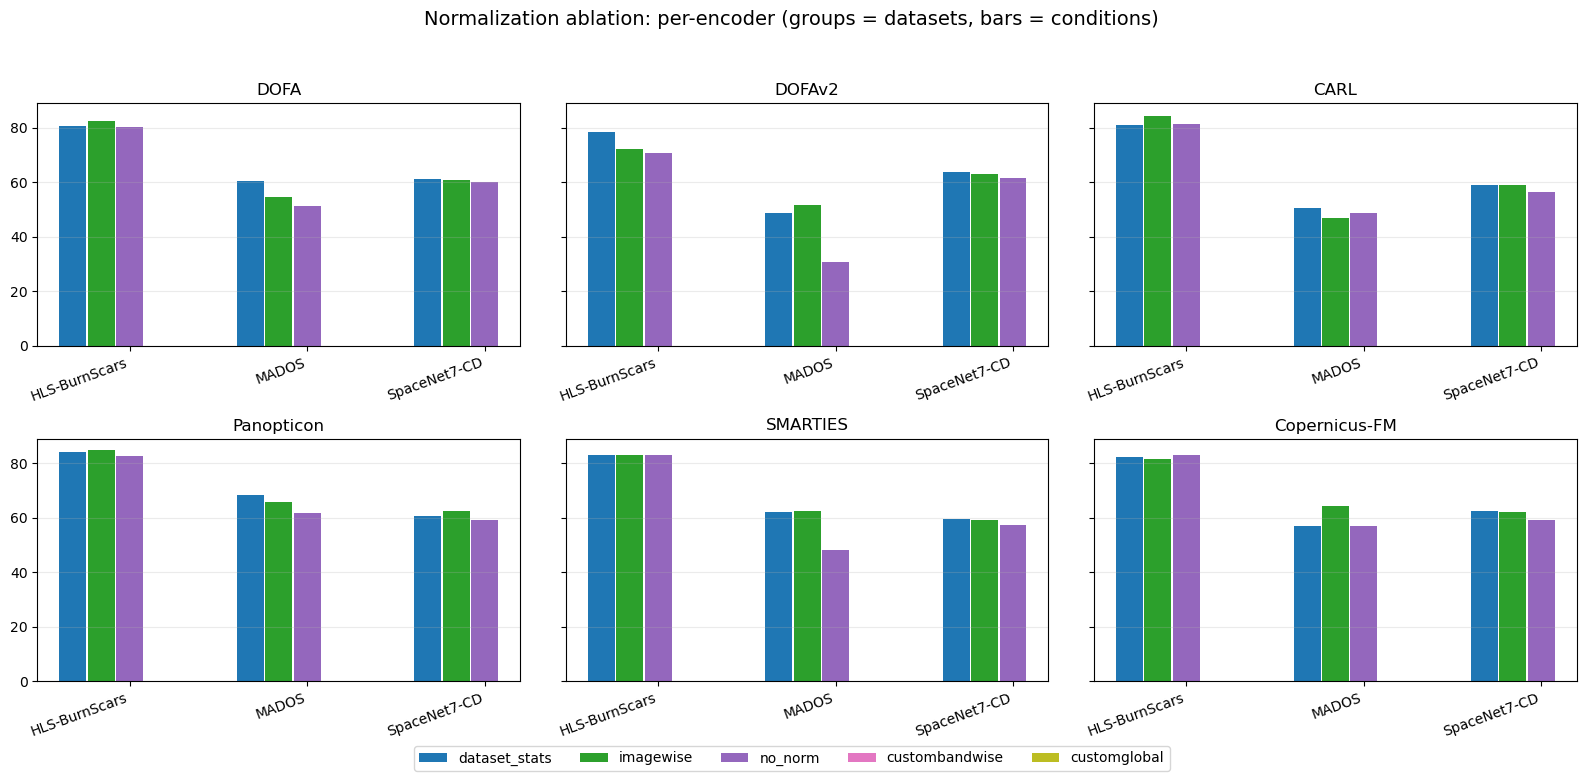

In [17]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

encs = ABL_ENCODERS_DISPLAY
dsets = ABL_DATASETS_DISPLAY
conds = CONDITIONS

pv = df_all.pivot_table(index=["encoder", "condition"], columns="dataset", values="test_mIoU", aggfunc="max")

n_rows, n_cols = 2, 3
fig, axs = plt.subplots(n_rows, n_cols, figsize=(16, 8), sharey=True)
axs = axs.ravel()

n_d = len(dsets)
n_c = len(conds)
total_w = 0.8
bar_w = total_w / max(1, n_c)

try:
    colors = plt.colormaps["tab10"]
except AttributeError:
    colors = plt.cm.get_cmap("tab10")

for i, enc in enumerate(encs):
    ax = axs[i]
    x = np.arange(n_d)
    for j, cond in enumerate(conds):
        vals = []
        for ds in dsets:
            try:
                v = pv.loc[(enc, cond), ds]
            except KeyError:
                v = np.nan
            vals.append(v)
        offset = (j - (n_c - 1) / 2) * bar_w
        ax.bar(x + offset, vals, width=bar_w * 0.95, color=colors(j / n_c), label=cond if i == 0 else None)
    ax.set_xticks(x)
    ax.set_xticklabels(dsets, rotation=20, ha="right")
    ax.set_title(enc)
    ax.grid(axis="y", alpha=0.25)

for k in range(len(encs), len(axs)):
    axs[k].axis("off")

fig.suptitle("Normalization ablation: per-encoder (groups = datasets, bars = conditions)", fontsize=14)
fig.legend(conds, ncol=min(len(conds), 5), bbox_to_anchor=(0.5, 0.02), loc="lower center")
fig.tight_layout(rect=[0, 0.05, 1, 0.95])
fig.savefig("abl_norm_per_encoder.png", dpi=300, bbox_inches="tight")
display(fig)
plt.close(fig)

## Missing runs check

In [18]:
expected = [
    (enc, ds, cond)
    for cond in CONDITIONS
    for enc in ABL_ENCODERS_DISPLAY
    for ds in ABL_DATASETS_DISPLAY
]

if df_all.empty:
    print("No data to check.")
else:
    present = set(zip(df_all["encoder"], df_all["dataset"], df_all["condition"]))
    missing = [(enc, ds, cond) for (enc, ds, cond) in expected if (enc, ds, cond) not in present]

    if not missing:
        print("All expected runs are present.")
    else:
        missing_df = pd.DataFrame(missing, columns=["encoder", "dataset", "condition"])
        print(f"{len(missing)} missing runs:")
        display(missing_df)

36 missing runs:


,encoder,dataset,condition
0,DOFA,HLS-BurnScars,custombandwise
1,DOFA,MADOS,custombandwise
2,DOFA,SpaceNet7-CD,custombandwise
3,DOFAv2,HLS-BurnScars,custombandwise
4,DOFAv2,MADOS,custombandwise
5,DOFAv2,SpaceNet7-CD,custombandwise
6,CARL,HLS-BurnScars,custombandwise
7,CARL,MADOS,custombandwise
8,CARL,SpaceNet7-CD,custombandwise
9,Panopticon,HLS-BurnScars,custombandwise
